# Implementing a new solver

## Objectives Summary

- Understand what metafspm hands to a solver, and what it expects back.
- Write a complete solver from the abstract interface (`AbstractSolver`): a plain Newton method.
- Write a new solver by replacing one ingredient of an existing one: Newton with a preconditioned conjugate gradient.
- Plug the new solver into a component without rewriting its equations, and run it in the soil–plant–atmosphere scene.

This tutorial reuses the plant water transport of the soil_plant_atmosphere example (`components.py`), introduced in `tutorial_fspm2026_general_usage.ipynb`.

## What a solver receives and returns

A component declares its equations in a `@graph_system` and names a solver class. At each solve, metafspm:

1. builds a **spec** (`GraphDAESpec`), the description of the system on the current graph;
2. instantiates the solver class with a `SolverConfig`, filled from the `@graph_system` arguments (`max_iter`, `tol`, `linesearch`, ...);
3. calls `solver.step_once(spec, previous_node_fields, dt)`, which returns the **packed vector** of converged unknowns;
4. calls `solver.derive_outputs(...)` for the `@graph_output`s, and writes everything back to the data structure.

A solver therefore never touches the data structure: it only works on the spec. The spec gives:

| member | what it is |
|---|---|
| `spec.pack_unknowns()` | the current unknowns as one vector: the node fields, then the edge fields (then the pools) |
| `spec.unpack_unknowns(x)` | the vector split back into `{field: array}` for nodes and edges |
| `spec.residual(x, previous_node_fields, dt)` | R(x): every equation, written as residual = 0 |
| `spec.jacobian(x, previous_node_fields, dt)` | ∂R/∂x, a sparse matrix (analytic, or by finite differences) |
| `spec.graph.n_nodes`, `spec.graph.n_edges` | the size of the graph |
| `spec.unknowns.node_fields`, `.edge_fields`, `.pool_fields` | the names of the unknowns, in packing order |

`previous_node_fields` and `dt` are only passed through to the residual: they carry the time terms of transient systems. A solver for steady systems can ignore them, as long as it passes them on.

In [1]:
from dataclasses import dataclass

import numpy as np
import pandas as pd
from scipy.sparse import diags
from scipy.sparse.linalg import cg, spsolve

from openalea.metafspm.solve.solver import AbstractSolver, NewtonSolver
from openalea.metafspm.solve.decorator import graph_system

## A complete solver from the abstract interface

`AbstractSolver` asks for one method only, `step_once`. Here is a plain Newton method: evaluate the residual, stop when its largest entry is below the tolerance, else solve J δ = −R and update.

The solver is instantiated anew at each solve, so what we want to inspect afterwards (the residual at each iteration) is kept in a class attribute, `history`.

In [2]:
class MinimalNewtonSolver(AbstractSolver):
    """Newton's method on the whole system, with a direct sparse linear solve at each iteration."""
    history = []                                   # one list of residual norms per solve

    def step_once(self, spec, previous_node_fields=None, dt=None):
        x = spec.pack_unknowns()                   # the initial guess: the current values
        norms = []
        for _ in range(self.config.max_iter):
            residual = spec.residual(x, previous_node_fields, dt)
            norms.append(np.abs(residual).max())
            if norms[-1] < self.config.tol:
                type(self).history.append(norms)
                return x
            jacobian = spec.jacobian(x, previous_node_fields, dt)
            x = x + spsolve(jacobian.tocsc(), -residual)
        raise RuntimeError(f"{type(self).__name__} did not converge in {self.config.max_iter} iterations "
                           f"(largest residual {norms[-1]:.1e})")

## Giving a component a new solver

The solver is chosen in the `@graph_system` decorator. To try a solver on existing equations, we do not rewrite them:
we subclass the example's component and decorate the same equations again with another solver.
`components.PlantWaterTransport._flow._inner_cls` is the class holding the equations (balance, Darcy law, boundary conditions, outputs).

The class must keep the name `PlantWaterTransport`, since translators identify components by class name.

In [3]:
import components

FLOW_EQUATIONS = components.PlantWaterTransport._flow._inner_cls


def plant_transport(solver):
    """The example's plant water transport, solved with *solver*."""
    @dataclass
    class PlantWaterTransport(components.PlantWaterTransport):
        _flow = graph_system(node_unknowns=["water_potential"], edge_unknowns=["water_flux"], solver=solver,
                             schedule_as="state")(FLOW_EQUATIONS)
    return PlantWaterTransport

To test a solver, a scene is not needed: one seedling, with a fixed soil water potential, is enough.
`one_seedling` builds the seedling with the example's structural component, couples it to the transport, runs both once and returns the water potentials.

In [4]:
from openalea.metafspm.coupling.composite_wrapper import CompositeModel
from openalea.metafspm.coupling.translator import Translator
from openalea.metafspm.data_structure.data_api import MPGDataStructure
from openalea.metafspm.scene.population import build_population
from components import SeedlingStructure

PLANT_TRANSLATOR = Translator().link("PlantWaterTransport", "conductance", "SeedlingStructure", {"k": 1.})


def seedling_water(transport_class):
    """The example's plant model (SeedlingWater), with the given transport."""
    class SeedlingWater(CompositeModel):
        initiators = (SeedlingStructure,)
        from_scale = "SubOrgan"
        nodes = "Compartment"

        def __init__(self, data_structure, time_step):
            self.structure = SeedlingStructure(data_structure=data_structure, time_step=time_step)
            self.transport = transport_class(data_structure=data_structure, time_step=time_step)
            self.declare_data_and_couple_components(translator_path=PLANT_TRANSLATOR,
                                                    components=(self.structure, self.transport))

        def run(self):
            self.structure()
            self.transport()
    return SeedlingWater


def one_seedling(transport_class, soil_water_potential=-0.05):
    """Water potentials (MPa) of one seedling's Compartments, the soil held at *soil_water_potential*."""
    table = pd.DataFrame([dict(x=0., y=0., z=0., rotation=0., scenario={"parameters": {}})])
    g, _ = build_population(table, initiators=(SeedlingStructure,))
    g.convert_properties_to_arraydict()
    data_structure = MPGDataStructure(g, from_scale=g.scales.SubOrgan, nodes="Compartment")
    model = seedling_water(transport_class)(data_structure=data_structure, time_step=1)
    n = len(data_structure.get("soil_water_potential"))
    data_structure.set("soil_water_potential", np.full(n, soil_water_potential))
    model.run()
    return np.array(data_structure.get("water_potential"))

The reference is the example's component, solved with metafspm's `NewtonSolver`. The new solver must give the same water potentials.

In [5]:
reference = one_seedling(components.PlantWaterTransport)
psi = one_seedling(plant_transport(MinimalNewtonSolver))

print(f"largest difference with NewtonSolver: {np.abs(psi - reference).max():.1e} MPa")
print("residual at each iteration:", ", ".join(f"{norm:.1e}" for norm in MinimalNewtonSolver.history[-1]))

largest difference with NewtonSolver: 1.6e-13 MPa
residual at each iteration: 8.6e-03, 4.5e-11


The system is linear (the conductances do not depend on Ψ), so Newton converges in a single iteration.

## A new solver from an existing one

Writing the whole iteration is rarely needed. `NewtonSolver` already handles the iteration, the tolerance, the optional line search, and the time terms. Its linear solve is a separate method, `_linear_step(jacobian, residual, spec)`, returning δ with J δ = −R.
Overriding it alone gives a new solver.

**The method.** The unknowns are the node potentials Ψ and the edge fluxes j. With the Jacobian split in blocks,

$$\begin{pmatrix} A & B \\ C & D \end{pmatrix} \begin{pmatrix} \delta_\Psi \\ \delta_j \end{pmatrix} = -\begin{pmatrix} R_\Psi \\ R_j \end{pmatrix}$$

the Darcy law of an edge only involves that edge's own flux, so D is diagonal and the fluxes can be eliminated:

$$(A - B D^{-1} C)\, \delta_\Psi = -R_\Psi + B D^{-1} R_j, \qquad \delta_j = D^{-1}(-R_j - C\, \delta_\Psi)$$

The reduced matrix is a weighted graph Laplacian plus the boundary terms: symmetric and positive definite here. We solve it with a **conjugate gradient** preconditioned by its diagonal (Jacobi), an iterative method that scales to large graphs.
Conjugate gradient needs a symmetric matrix. When D is not diagonal, when the reduced matrix is not symmetric (a Dirichlet condition replaces a balance row and breaks the symmetry), or when the system has pool unknowns, the solver falls back to the parent's direct solve.

**Options.** `SolverConfig` only holds the options that `@graph_system` passes. A solver's own options are class attributes, here `cg_rtol`, the relative tolerance of the inner conjugate gradient. A subclass changes them.

In [6]:
class PCGNewtonSolver(NewtonSolver):
    """
    Newton's method, the linear system solved by a Jacobi-preconditioned conjugate gradient on the node unknowns,
    after eliminating the edge unknowns.
    """
    cg_rtol = 1e-6                                 # relative tolerance of the inner conjugate gradient
    history = []                                   # (residual norms, CG iterations) per solve

    def step_once(self, spec, previous_node_fields=None, dt=None):
        self.norms, self.cg_iterations = [], []
        x = super().step_once(spec, previous_node_fields, dt)
        self.norms.append(np.abs(spec.residual(x, previous_node_fields, dt)).max())   # the converged residual
        type(self).history.append((self.norms, self.cg_iterations))
        return x

    def _linear_step(self, jacobian, residual, spec=None):
        self.norms.append(np.abs(residual).max())
        jacobian = jacobian.tocsr()
        n = spec.graph.n_nodes * len(spec.unknowns.node_fields)           # node unknowns come first
        A, B = jacobian[:n, :n], jacobian[:n, n:]
        C, D = jacobian[n:, :n], jacobian[n:, n:]
        d = D.diagonal()
        if spec.unknowns.pool_fields or np.any(d == 0.) or (D - diags(d)).count_nonzero():
            return super()._linear_step(jacobian, residual, spec)          # not eliminable: the direct solve

        D_inv = diags(1. / d)
        reduced = (A - B @ D_inv @ C).tocsr()
        if abs(reduced - reduced.T).max() > 1e-6 * abs(reduced).max():
            return super()._linear_step(jacobian, residual, spec)          # not symmetric (e.g. a Dirichlet row); 1e-6: finite-difference noise
        r_nodes, r_edges = residual[:n], residual[n:]
        iterations = [0]
        delta_nodes, info = cg(reduced, -(r_nodes - B @ (D_inv @ r_edges)), rtol=self.cg_rtol,
                               M=diags(1. / reduced.diagonal()),
                               callback=lambda _: iterations.__setitem__(0, iterations[0] + 1))
        if info > 0:
            raise RuntimeError(f"conjugate gradient did not converge in {info} iterations")
        self.cg_iterations.append(iterations[0])
        delta_edges = D_inv @ (-r_edges - C @ delta_nodes)
        return np.concatenate([delta_nodes, delta_edges])


class LoosePCGNewtonSolver(PCGNewtonSolver):
    """The same, with an inner tolerance 10 000 times looser."""
    cg_rtol = 1e-2
    history = []

In [7]:
seedling_norms = {"MinimalNewtonSolver": MinimalNewtonSolver.history[-1]}
for solver in (PCGNewtonSolver, LoosePCGNewtonSolver):
    psi = one_seedling(plant_transport(solver))
    norms, cg_iterations = solver.history[-1]
    print(f"{solver.__name__}: largest difference with NewtonSolver {np.abs(psi - reference).max():.1e} MPa, "
          f"{len(norms) - 1} Newton iterations, CG iterations {cg_iterations}")
    seedling_norms[solver.__name__] = norms

PCGNewtonSolver: largest difference with NewtonSolver 7.1e-09 MPa, 2 Newton iterations, CG iterations [49, 49]
LoosePCGNewtonSolver: largest difference with NewtonSolver 7.1e-09 MPa, 4 Newton iterations, CG iterations [42, 10, 12, 40]


With an inexact inner solve, Newton needs more iterations, but each costs fewer CG iterations: this is the trade-off of **inexact Newton** methods. Both converge to the same solution, within the Newton tolerance (`tol=1e-10` on the residual).

## The new solver in the soil–plant–atmosphere scene

The plant model now uses the new solver; the soil keeps its own. Nothing else changes in the scene.

In [8]:
from openalea.metafspm.scene.scene import Scene
from models import SCENE_TRANSLATOR, Soil, largest_change, root_surface_mappings

PCGNewtonSolver.history.clear()
table = pd.DataFrame([dict(plant="seedling", model=seedling_water(plant_transport(PCGNewtonSolver)),
                           x=0.1, y=0.1, z=0., rotation=0., scenario={"parameters": {}})])
table.attrs.update(xrange=0.2, yrange=0.2)
stop = largest_change(tolerance=1e-6)
scene_instance = Scene(table, environment=[Soil], translator=SCENE_TRANSLATOR, time_step=3600,
                       mappings=root_surface_mappings, stop_when=stop)
scene_instance.simulate(20)
scene_solves = list(PCGNewtonSolver.history)                    # the plant solves of the scene, kept for the plots

plant = scene_instance.populations[0].data_structure
soil = scene_instance.environment[0].grid
print(f"converged in {scene_instance.iteration} steps, {len(scene_solves)} plant solves; "
      f"transpiration {plant.get('evaporation').sum():.4f} mm3 s-1, leaf Ψ down to {plant.get('water_potential').min():.2f} MPa")

converged in 7 steps, 7 plant solves; transpiration 0.0755 mm3 s-1, leaf Ψ down to -2.71 MPa


The scene converges as with `NewtonSolver` (`tutorial_fspm2026_general_usage.ipynb`: 7 steps, 0.0755 mm³ s⁻¹).

## The new solver on a toy graph system

A solver is not tied to plants: it applies to any `@graph_system`. Here is a single component on the simplest graph, a chain of 10 cells (an `ArrayDataStructure`: the cells are the nodes, the faces between them the edges).

Water enters the first cell from a reservoir, k_r (Ψ_r − Ψ), and each cell loses a fixed sink s. The faces have a conductance k. The equations are those of the plant transport: a balance, a Darcy law, and boundary conditions written as inflows.

In [9]:
from openalea.metafspm.coupling.component import FunctionalComponent, input_variable, parameter, state_variable
from openalea.metafspm.data_structure.data_api import ArrayDataStructure
from openalea.metafspm.solve.decorator import boundary_condition, edge_law, node_balance


@dataclass
class ToyChain(FunctionalComponent):
    """Steady flow along a chain of cells, fed by a reservoir at one end, with a uniform sink."""
    potential: float = state_variable(unit="MPa", unit_comment="", description="Potential of a cell.",
                                      min_value=-10., max_value=0., value_comment="", references="", DOI=[],
                                      initialize=0., location="cell", state_variable_type="intensive")
    flux: float = state_variable(unit="mm3 s-1", unit_comment="", description="Flux through a face, towards the end.",
                                 min_value=-10., max_value=10., value_comment="", references="", DOI=[],
                                 initialize=0., location="edge", state_variable_type="extensive")
    conductance: float = parameter(unit="mm3 s-1 MPa-1", unit_comment="", description="Conductance of a face.",
                                   min_value=0., max_value=100., value_comment="", references="", DOI=[],
                                   by="ToyChain", default=2., location="edge")
    sink: float = parameter(unit="mm3 s-1", unit_comment="", description="Water taken up in each cell.",
                            min_value=0., max_value=10., value_comment="", references="", DOI=[],
                            by="ToyChain", default=0.1, location="cell")
    reservoir_potential: float = parameter(unit="MPa", unit_comment="", description="Potential of the reservoir.",
                                           min_value=-10., max_value=0., value_comment="", references="", DOI=[],
                                           by="ToyChain", default=0.)
    reservoir_conductance: float = parameter(unit="mm3 s-1 MPa-1", unit_comment="",
                                             description="Conductance between the reservoir and its cell.",
                                             min_value=0., max_value=100., value_comment="", references="", DOI=[],
                                             by="ToyChain", default=5.)
    is_reservoir: float = input_variable(unit="-", unit_comment="", description="1 at the cell fed by the reservoir.",
                                         min_value=0., max_value=1., value_comment="", references="", DOI=[],
                                         by="the user", initialize=0., location="cell",
                                         state_variable_type="descriptor")

    @graph_system(node_unknowns=["potential"], edge_unknowns=["flux"], solver=PCGNewtonSolver, schedule_as="state")
    class _flow:
        @node_balance(field="potential")
        def _balance(self, flux):
            return np.asarray(self._graph_view.incidence @ flux).reshape(-1)        # the outflows

        @edge_law(field="flux", explicit=True)
        def _darcy(self, potential, conductance):
            return conductance * np.asarray(self._graph_view.incidence.T @ potential).reshape(-1)

        @boundary_condition("node", "neumann", field="potential", filters={"is_reservoir": ">0"})
        def _reservoir(self, potential, reservoir_potential, reservoir_conductance):
            return reservoir_conductance * (reservoir_potential - potential)       # an inflow

        @boundary_condition("node", "neumann", field="potential")
        def _sink(self, sink):
            return -sink                                                           # a loss, in every cell

Define, instantiate and solve: the data structure is a chain of 10 cells, the first one fed by the reservoir.

The time step matters even for a steady system: a component runs simulation_time_step / time_step times per call, and the scene above set the simulation time step to 3600 s. With time_step=1, the toy would be solved 3600 times.

In [10]:
n_cells = 10
chain = ArrayDataStructure(shape=(n_cells,))
toy_chain = ToyChain(data_structure=chain, time_step=3600)       # the simulation time step: one solve per call
chain.set("is_reservoir", np.r_[1., np.zeros(n_cells - 1)])
toy_chain()

potential = np.asarray(chain.get("potential")).reshape(-1)
norms, cg_iterations = PCGNewtonSolver.history[-1]
print("potential (MPa):", np.round(potential, 3))
print("flux (mm3 s-1): ", np.round(np.asarray(chain.get("flux")).reshape(-1), 3))
print(f"{len(norms) - 1} Newton iterations, CG iterations {cg_iterations}")

potential (MPa): [-0.2  -0.65 -1.05 -1.4  -1.7  -1.95 -2.15 -2.3  -2.4  -2.45]
flux (mm3 s-1):  [0.9 0.8 0.7 0.6 0.5 0.4 0.3 0.2 0.1]
2 Newton iterations, CG iterations [10, 10]


The exact solution checks the solver. All the water, n s, enters through the reservoir, so Ψ₀ = Ψ_r − n s / k_r. Face i carries the sinks of the cells beyond it, (n − 1 − i) s, so the potential drops by that over k from one cell to the next.

In [11]:
s, k, k_r = toy_chain.sink, toy_chain.conductance, toy_chain.reservoir_conductance
carried = (n_cells - 1 - np.arange(n_cells - 1)) * s                    # the flux through each face
exact = toy_chain.reservoir_potential - n_cells * s / k_r - np.r_[0., np.cumsum(carried / k)]
print(f"largest difference with the exact solution: {np.abs(potential - exact).max():.1e} MPa")

largest difference with the exact solution: 4.4e-16 MPa


## Plotting the results

Left, the residual at each Newton iteration of the one-seedling solves. The direct solve converges in one iteration, and the conjugate gradient at 1e-6 in two, its tolerance leaving a small residual. The loose one needs four.
Middle, the conjugate gradient iterations of each plant solve in the scene.
Right, the toy chain's potentials against the exact solution.

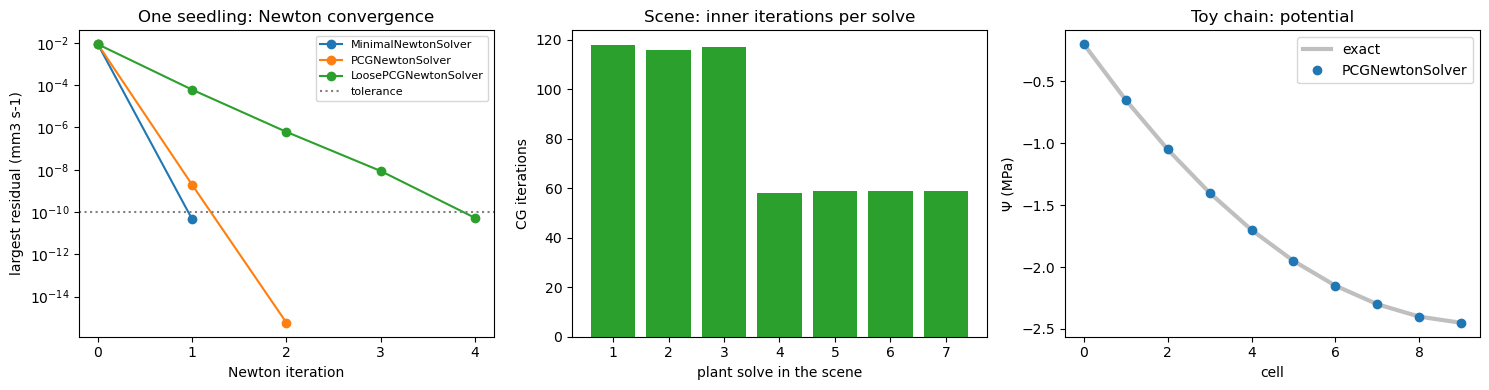

In [12]:
%matplotlib inline
import matplotlib.pyplot as plt

fig, (left, middle, right) = plt.subplots(1, 3, figsize=(15, 4))

for name, norms in seedling_norms.items():
    left.semilogy(range(len(norms)), norms, marker="o", label=name)
left.axhline(1e-10, color="grey", linestyle=":", label="tolerance")
left.set(xlabel="Newton iteration", ylabel="largest residual (mm3 s-1)", title="One seedling: Newton convergence")
left.xaxis.get_major_locator().set_params(integer=True)
left.legend(fontsize=8)

scene_cg = [sum(cg_iterations) for _, cg_iterations in scene_solves]
middle.bar(range(1, len(scene_cg) + 1), scene_cg, color="tab:green")
middle.set(xlabel="plant solve in the scene", ylabel="CG iterations", title="Scene: inner iterations per solve")

right.plot(range(n_cells), exact, color="grey", linewidth=3, alpha=0.5, label="exact")
right.plot(range(n_cells), potential, "o", color="tab:blue", label="PCGNewtonSolver")
right.set(xlabel="cell", ylabel="Ψ (MPa)", title="Toy chain: potential")
right.legend()

fig.tight_layout()
plt.show()